# The DigiCam trigger: trigger traces, patch7, and how to emulate it

The SST-1M camera (DigiCam) triggers in its FPGAs, on the sums of groups of pixels. This notebook shows
what the camera records of its trigger, how the **patch7** trigger running on the telescopes works, and how
to emulate it from the raw data and from simulations with `sst1mpipe.trigger`.

The trigger chain, per readout sample (4 ns):

1. **Patches**: the 1296 pixels are grouped in 432 *patches* of 3 neighbouring pixels.
2. **Trigger input traces** (`trigger_input_traces`): for each patch, the sum of its 3 pixels after
   subtraction of their baseline, clipped to 0–255 ADC (the FADC output of the patch).
3. **patch7**: for each patch, the sum of the input traces of the *cluster* made of the patch and its
   6 neighbours (fewer at the camera edge).
4. **Trigger output** (`trigger_output_patch7`): 1 where this cluster sum is above the threshold. The camera
   triggers if any cluster fires.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from ctapipe.io import EventSource
from ctapipe.visualization import CameraDisplay

from sst1mpipe.instrument.camera import DigiCam
from sst1mpipe.resources import TEST_DATA_DIR
from sst1mpipe.trigger import TriggerEmulator, TriggerPatch7Emulator, TriggerPatch19Emulator, TriggerTDSCANEmulator
from sst1mpipe.trigger.emulator import BASELINE_SAMPLE

## 1. The trigger traces of the raw data

[SST1MEventSource](https://sst-1m-collaboration.github.io/sst1mpipe/event_sources.html#sst1mpipe.io.sst1m_event_source.SST1MEventSource) fills, for each telescope event, the trigger traces of the camera in `event.r0.tel[tel_id]`,
as arrays (432 patches, n_samples). They are in patch order (`patch_sw_id`) for both telescopes, with the
wrongly connected modules moved back as for the pixels:

| Field | Content |
|---|---|
| `trigger_input_traces` | FADC output of each patch (0–255 ADC) |
| `trigger_output_patch7` | patch7 output of the cluster centred on each patch (0 or 1) |
| `trigger_output_patch19` | patch19 output (not used on the telescopes: always 0) |
| `trigger_output_muon` | output of the muon trigger |

We read a Mrk 421 run of SST1M-1 and keep the shower event with the most fired clusters.

In [2]:
tel_id = 21
input_file = TEST_DATA_DIR / "zfits" / "SST1M1_20260120_1179.fits.fz"

with EventSource(input_file, max_events=200) as source:
    geometry = source.subarray.tel[tel_id].camera.geometry
    events = [event for event in source if event.trigger.event_type.name == "SUBARRAY"]

event = max(events, key=lambda event: event.r0.tel[tel_id].trigger_output_patch7.any(axis=1).sum())
r0 = event.r0.tel[tel_id]
traces = np.asarray(r0.trigger_input_traces).astype(int)
camera_output = np.asarray(r0.trigger_output_patch7).astype(bool)
print("event", event.index.event_id)
print("trigger_input_traces ", traces.shape, traces.dtype, "max", traces.max())
print("trigger_output_patch7", camera_output.shape, "fired clusters:", np.flatnonzero(camera_output.any(axis=1)))

event 25077897
trigger_input_traces  (432, 50) int64 max 255
trigger_output_patch7 (432, 50) fired clusters: [117 128 129 130 140 141 152 153 154 163 164 165 175 176 177 178 187 188
 189 199 200 201 210 211 212 213 223 224 225 234 235 236 247 248 258 259
 271]


A patch is 3 pixels: `DigiCam.patch_matrix` (432 × 1296, sparse) gives the pixels of each patch. Its transpose
puts a value per patch on its 3 pixels, to draw the patches on the camera.

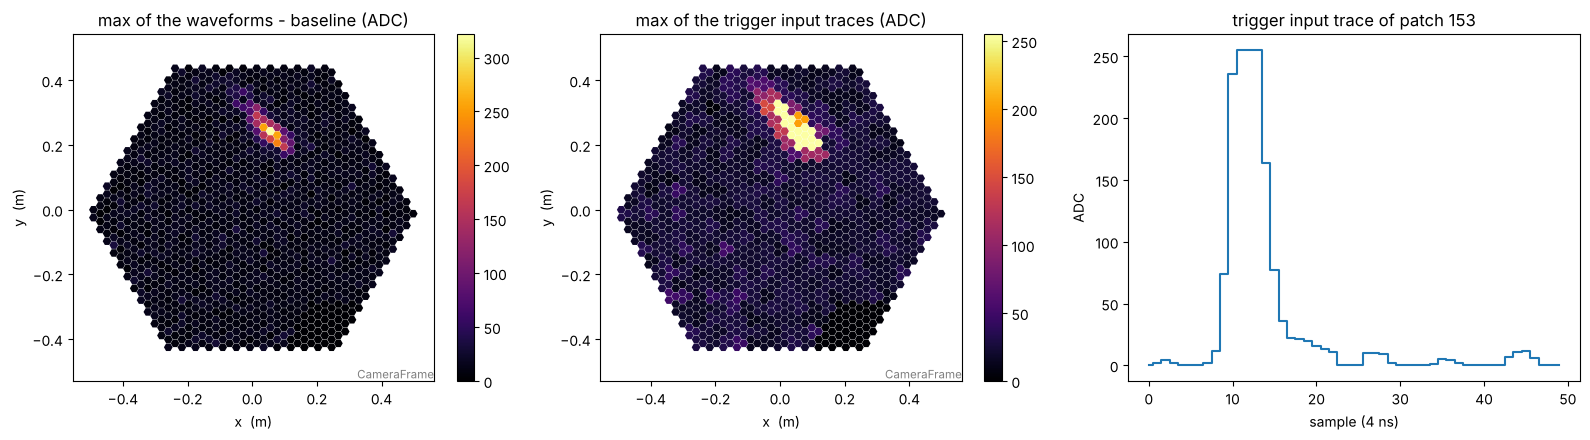

In [3]:
def patches_on_pixels(values):
    # value of each patch shown on its 3 pixels
    return DigiCam.patch_matrix.T.dot(values)


peak_patch = np.unravel_index(traces.argmax(), traces.shape)[0]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
CameraDisplay(geometry, image=r0.waveform[0].max(axis=1) - r0.pedestal, ax=axes[0], title="max of the waveforms - baseline (ADC)").add_colorbar(ax=axes[0])
CameraDisplay(geometry, image=patches_on_pixels(traces.max(axis=1)), ax=axes[1], title="max of the trigger input traces (ADC)").add_colorbar(ax=axes[1])
axes[2].plot(traces[peak_patch], drawstyle="steps-mid")
axes[2].set(xlabel="sample (4 ns)", ylabel="ADC", title=f"trigger input trace of patch {peak_patch}")
plt.tight_layout()

## 2. The input traces are the patches of the pixel waveforms

The input traces can be rebuilt from the R0 waveforms: for each pixel, the sample minus the floor of its
baseline (`r0.pedestal`), summed over the 3 pixels of the patch and clipped to 0–255
(`TriggerEmulator._compute_trigger_traces`). Pixels without data (`pixel_flags == 0`, dead modules) do not
contribute.

The FPGA updates its baseline continuously, while the event stores a single value per pixel: the rebuilt
traces are identical to the camera ones at the sample `BASELINE_SAMPLE` = 6, and within ±1 ADC on most
of the others.

sample 6: identical patches 100.0%
all samples: identical samples 91.9%, mean squared error per trace 5.3 ADC^2


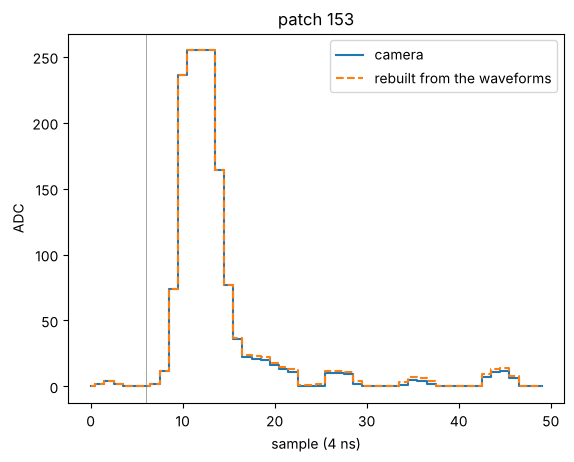

In [4]:
rebuilt = TriggerEmulator._compute_trigger_traces(r0.waveform[0], r0.pedestal, pixel_flags=r0.pixel_flags)
print(f"sample {BASELINE_SAMPLE}: identical patches {np.mean(rebuilt[:, BASELINE_SAMPLE] == traces[:, BASELINE_SAMPLE]):.1%}")
print(f"all samples: identical samples {np.mean(rebuilt == traces):.1%}, "
      f"mean squared error per trace {np.mean(np.sum((rebuilt - traces) ** 2, axis=1)):.1f} ADC^2")

plt.plot(traces[peak_patch], drawstyle="steps-mid", label="camera")
plt.plot(rebuilt[peak_patch], "--", drawstyle="steps-mid", label="rebuilt from the waveforms")
plt.axvline(BASELINE_SAMPLE, color="grey", lw=0.5)
plt.xlabel("sample (4 ns)")
plt.ylabel("ADC")
plt.title(f"patch {peak_patch}")
plt.legend();

## 3. How patch7 works

`DigiCam.cluster_7_matrix` (432 × 432, sparse) gives, for each cluster, its patches: the central patch and its
6 neighbours. The cluster sum of all the clusters at all the samples is a single matrix product with the input
traces. The cluster fires where this sum is above the threshold of the telescope.

cluster 153: patches [129, 140, 141, 153, 164, 165, 177]


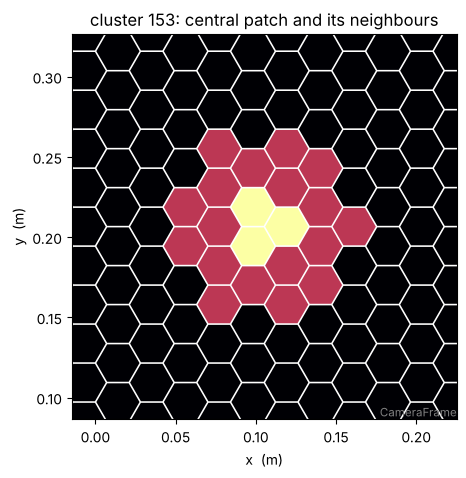

In [5]:
cluster = peak_patch
cluster_patches = DigiCam.cluster_7_matrix[cluster].indices
print(f"cluster {cluster}: patches {cluster_patches.tolist()}")

shown = np.zeros(432)
shown[cluster_patches] = 1
shown[cluster] = 2
fig, ax = plt.subplots(figsize=(5, 5))
display = CameraDisplay(geometry, image=patches_on_pixels(shown), ax=ax, title=f"cluster {cluster}: central patch and its neighbours")
display.set_limits_minmax(0, 2)
centre = DigiCam.patch_matrix[cluster].indices
x, y = geometry.pix_x[centre].mean().to_value("m"), geometry.pix_y[centre].mean().to_value("m")
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(x - 0.12, x + 0.12)
ax.set_ylim(y - 0.12, y + 0.12);

`TriggerPatch7Emulator` does this product (`scores`) and the comparison to the threshold (`trigger_output`).
The threshold is a required, per-telescope parameter. The patch7 threshold of this run was 185: with it, the
emulated output is the camera output, sample by sample.

emulated output identical to the camera output: True


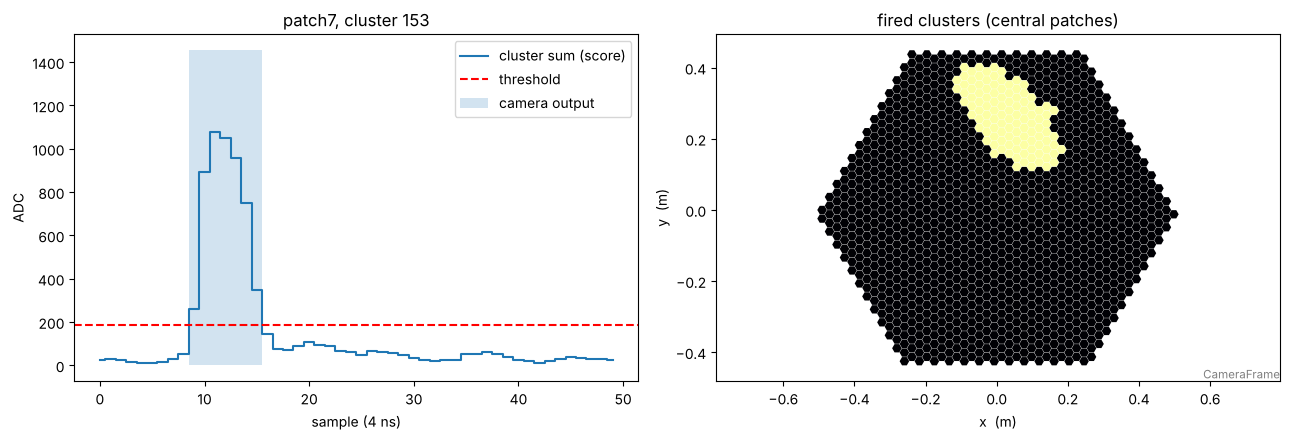

In [6]:
patch7 = TriggerPatch7Emulator(subarray=source.subarray, threshold=185)
emulated_output, scores = patch7.trigger_output(traces, tel_id)
print("emulated output identical to the camera output:", np.array_equal(emulated_output, camera_output))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(scores[cluster], drawstyle="steps-mid", label="cluster sum (score)")
axes[0].axhline(185, color="red", ls="--", label="threshold")
axes[0].fill_between(np.arange(scores.shape[1]), 0, scores.max() * camera_output[cluster], step="mid", alpha=0.2, label="camera output")
axes[0].set(xlabel="sample (4 ns)", ylabel="ADC", title=f"patch7, cluster {cluster}")
axes[0].legend()
CameraDisplay(geometry, image=patches_on_pixels(camera_output.any(axis=1).astype(float)), ax=axes[1], title="fired clusters (central patches)")
plt.tight_layout()

## 4. Emulating the trigger of simulations

The simulations (sim_telarray) have no trigger traces: `trigger_traces` computes them from the R0 waveforms
and the simulated pedestal per sample, read from the camera monitoring of the simtel file. The trigger output
then follows as for the raw data. The `sst1mpipe-trigger` tool does this for a whole file
(configuration examples: `sst1mpipe/resources/config/sst1mpipe_trigger_emulator_{mc,data}.json`).

In [7]:
simtel_file = TEST_DATA_DIR / "simtel" / "gamma_point_200_800E3GeV_20_20deg_ATM52_300669.corsika.gz.NSBmed4.simtel.gz"

with EventSource(simtel_file, max_events=10) as simtel_source:
    patch7_mc = TriggerPatch7Emulator(subarray=simtel_source.subarray, threshold=242)
    for sim_event in simtel_source:
        for sim_tel_id in sim_event.r0.tel:
            monitoring = simtel_source.file_.camera_monitorings[sim_tel_id]
            pedestal = monitoring["pedestal"] / monitoring["n_ped_slices"]
            sim_traces = patch7_mc.trigger_traces(sim_event, sim_tel_id, pedestal=pedestal)
            sim_output, sim_scores = patch7_mc.trigger_output(sim_traces, sim_tel_id)
            print(f"event {sim_event.index.event_id:5d} tel {sim_tel_id}: max cluster sum {sim_scores.max():4d}, "
                  f"patch7 fires: {sim_output.any()}")

event   102 tel 1: max cluster sum  504, patch7 fires: True
event   115 tel 1: max cluster sum  505, patch7 fires: True
event   414 tel 1: max cluster sum  200, patch7 fires: False
event   414 tel 2: max cluster sum  319, patch7 fires: True
event   601 tel 2: max cluster sum  291, patch7 fires: True
event   802 tel 2: max cluster sum  436, patch7 fires: True
event   817 tel 1: max cluster sum  389, patch7 fires: True
event   916 tel 1: max cluster sum  236, patch7 fires: False
event   916 tel 2: max cluster sum  314, patch7 fires: True
event   917 tel 2: max cluster sum  276, patch7 fires: True
event  1008 tel 1: max cluster sum  351, patch7 fires: True
event  1008 tel 2: max cluster sum  633, patch7 fires: True
event  1009 tel 1: max cluster sum  375, patch7 fires: True
event  1009 tel 2: max cluster sum  939, patch7 fires: True


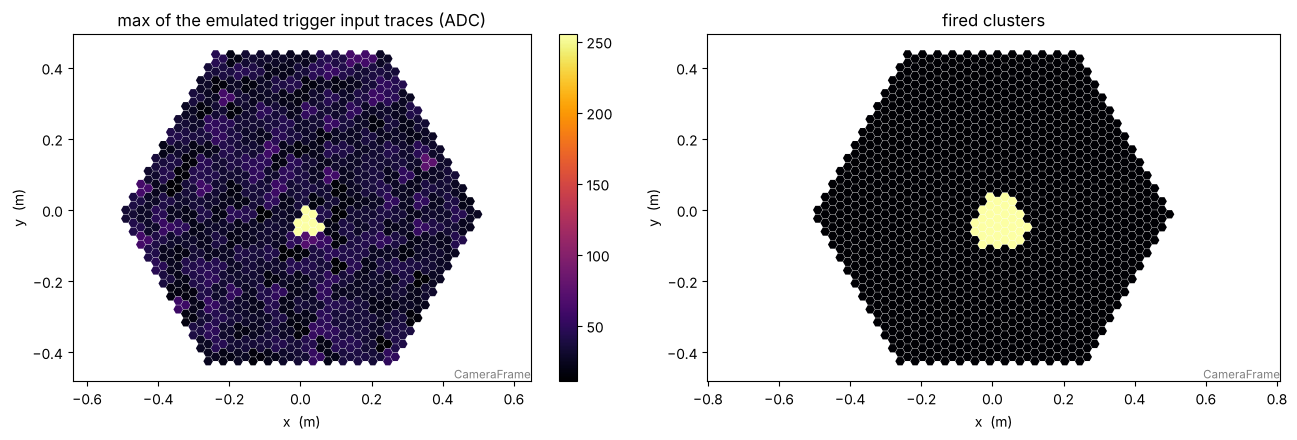

In [8]:
sim_geometry = simtel_source.subarray.tel[sim_tel_id].camera.geometry
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
CameraDisplay(sim_geometry, image=patches_on_pixels(sim_traces.max(axis=1)), ax=axes[0], title="max of the emulated trigger input traces (ADC)").add_colorbar(ax=axes[0])
CameraDisplay(sim_geometry, image=patches_on_pixels(sim_output.any(axis=1).astype(float)), ax=axes[1], title="fired clusters")
plt.tight_layout()

## 5. Other triggers

The emulators share the base class `TriggerEmulator`: a trigger is defined by its `scores` and its threshold.
Two other triggers can be studied on the same input traces:

- **patch19** (`TriggerPatch19Emulator`): the sum over clusters of 19 patches (`DigiCam.cluster_19_matrix`),
  for larger images. It is in the camera firmware but not used on the telescopes, so its recorded output is 0.
- **TDSCAN** (`TriggerTDSCANEmulator`): the candidate new firmware trigger. The traces are quantized to 4-bit
  codes and filtered in space (patch and neighbours, `DigiCam.neighbor_patch_matrix`) and time, in floating
  point or bit-exact fixed point.

In [9]:
import json

from traitlets.config import Config

from sst1mpipe.resources import CONFIG_DIR

# example thresholds: patch19 has no threshold of the telescopes
patch19 = TriggerPatch19Emulator(subarray=source.subarray, threshold=1500)
with open(CONFIG_DIR / "sst1mpipe_trigger_emulator_data.json") as f:
    tdscan = TriggerTDSCANEmulator(subarray=source.subarray, config=Config(json.load(f)))

for name, emulator in [("patch7", patch7), ("patch19", patch19), ("TDSCAN", tdscan)]:
    output, scores = emulator.trigger_output(traces, tel_id)
    print(f"{name:8s} max score {scores.max():8.2f}, threshold {emulator.threshold.tel[tel_id]:8.2f}, "
          f"fired clusters {output.any(axis=1).sum()}")

patch7   max score  1455.00, threshold   185.00, fired clusters 37
patch19  max score  2443.00, threshold  1500.00, fired clusters 16
TDSCAN   max score    15.75, threshold     8.75, fired clusters 23
